In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score

features = pd.read_csv("data/elliptic_txs_features.csv", header=None)
classes = pd.read_csv("data/elliptic_txs_classes.csv")

# Column 0 = txId, column 1 = time step, columns 2..166 = the 165 features
feat_cols = [f"f{i}" for i in range(2, 167)]
features.columns = ["txId", "time_step"] + feat_cols

df = features.merge(classes, on="txId")

# Keep labeled rows only; illicit (class "1") is the positive class
df = df[df["class"] != "unknown"].copy()
df["y"] = (df["class"] == "1").astype(int)

train = df[df["time_step"] <= 34]
test = df[df["time_step"] >= 35]

X_train, y_train = train[feat_cols], train["y"]
X_test, y_test = test[feat_cols], test["y"]

print(len(train), len(test))
print("illicit share train/test:", y_train.mean().round(3), y_test.mean().round(3))

29894 16670
illicit share train/test: 0.116 0.065


In [2]:
rf = RandomForestClassifier(n_estimators=50, max_features=50,
                            random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

pred = rf.predict(X_test)
print("Precision:", round(precision_score(y_test, pred), 3))
print("Recall:   ", round(recall_score(y_test, pred), 3))
print("Illicit F1:", round(f1_score(y_test, pred), 3))

Precision: 0.914
Recall:    0.724
Illicit F1: 0.808


    time_step  n_illicit  precision  recall     f1
0          35        182      0.978   0.956  0.967
1          36         33      0.868   1.000  0.930
2          37         40      0.963   0.650  0.776
3          38        111      0.990   0.901  0.943
4          39         81      0.904   0.926  0.915
5          40        112      0.926   0.670  0.777
6          41        116      0.991   0.922  0.955
7          42        239      0.955   0.799  0.870
8          43         24      0.000   0.000  0.000
9          44         24      0.077   0.042  0.054
10         45          5      0.000   0.000  0.000
11         46          2      0.125   0.500  0.200
12         47         22      0.000   0.000  0.000
13         48         36      0.000   0.000  0.000
14         49         56      0.250   0.018  0.033


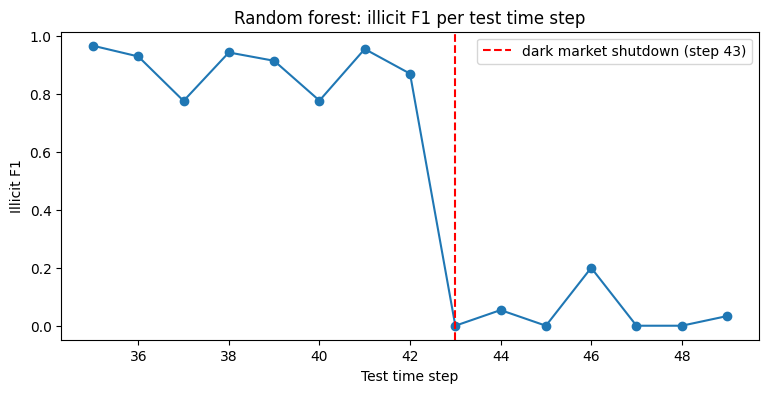

In [3]:
rows = []
for t in range(35, 50):
    m = test["time_step"] == t
    yt, yp = y_test[m], pred[m.values]
    rows.append({
        "time_step": t,
        "n_illicit": int(yt.sum()),
        "precision": precision_score(yt, yp, zero_division=0),
        "recall": recall_score(yt, yp, zero_division=0),
        "f1": f1_score(yt, yp, zero_division=0),
    })

per_step = pd.DataFrame(rows)
print(per_step.round(3))

plt.figure(figsize=(9, 4))
plt.plot(per_step["time_step"], per_step["f1"], marker="o")
plt.axvline(43, color="red", linestyle="--", label="dark market shutdown (step 43)")
plt.xlabel("Test time step")
plt.ylabel("Illicit F1")
plt.title("Random forest: illicit F1 per test time step")
plt.legend()
plt.show()

import os
os.makedirs("results", exist_ok=True)
per_step.to_csv("results/rf_baseline_per_step.csv", index=False)

In [4]:
test = test.copy()
test["p_illicit"] = rf.predict_proba(X_test)[:, 1]
test["pred"] = pred

rows = []
for t in range(35, 50):
    m = test["time_step"] == t
    rows.append({
        "time_step": t,
        "n_pred_illicit": int(test.loc[m, "pred"].sum()),
        "mean_p_true_illicit": test.loc[m & (test["y"] == 1), "p_illicit"].mean(),
        "mean_p_licit": test.loc[m & (test["y"] == 0), "p_illicit"].mean(),
    })

prob_summary = pd.DataFrame(rows)
print(prob_summary.round(3))
prob_summary.to_csv("results/rf_probability_summary.csv", index=False)

    time_step  n_pred_illicit  mean_p_true_illicit  mean_p_licit
0          35             178                0.943         0.049
1          36              38                0.947         0.060
2          37              27                0.639         0.040
3          38             101                0.881         0.055
4          39              83                0.887         0.063
5          40              81                0.658         0.088
6          41             108                0.881         0.076
7          42             200                0.795         0.072
8          43               5                0.103         0.091
9          44              13                0.146         0.112
10         45              10                0.140         0.096
11         46               8                0.470         0.079
12         47               2                0.064         0.067
13         48               0                0.050         0.053
14         49            